# Regresión Logística con Scikit-Learn
Informe de Machine Learning Supervisado - Notebook 1

Dataset: *Breast Cancer Wisconsin (Diagnostic)* incluido en scikit-learn.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, ConfusionMatrixDisplay, roc_curve, roc_auc_score, classification_report)
from sklearn.linear_model import LogisticRegression

## 1. Carga y exploración de datos

In [2]:
data = load_breast_cancer(as_frame=True)
X, y = data.data, data.target          # 0 = maligno, 1 = benigno
print(X.shape)
print(y.map({0: "Maligno", 1: "Benigno"}).value_counts())
X.head()

(569, 30)
target
Benigno    357
Maligno    212
Name: count, dtype: int64


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst radius,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,25.38,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,24.99,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,23.57,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,14.91,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,22.54,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678


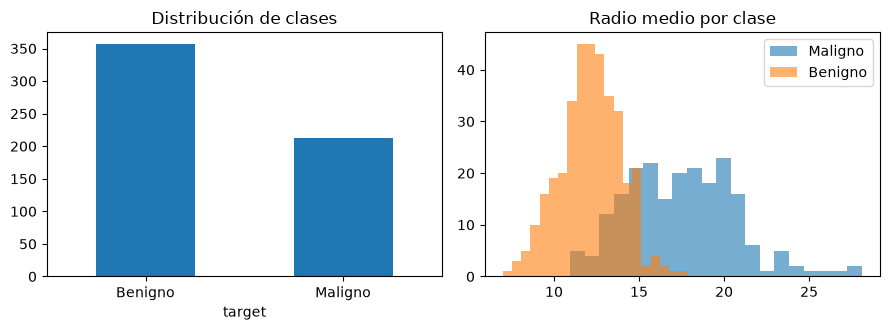

In [3]:
fig, ax = plt.subplots(1, 2, figsize=(9, 3.4))
y.map({0: "Maligno", 1: "Benigno"}).value_counts().plot.bar(ax=ax[0], rot=0)
ax[0].set_title("Distribución de clases")
for c, l in [(0, "Maligno"), (1, "Benigno")]:
    ax[1].hist(X.loc[y == c, "mean radius"], bins=20, alpha=.6, label=l)
ax[1].set_title("Radio medio por clase"); ax[1].legend()
plt.tight_layout(); plt.show()

## 2. Partición entrenamiento / prueba (75 % / 25 %, estratificada)

In [4]:
Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=0.25, random_state=42, stratify=y)
print(Xtr.shape, Xte.shape)

(426, 30) (143, 30)


## 3. Función sigmoide
La regresión logística modela P(y=1|x) = 1 / (1 + e^(-z)), con z = b0 + b1*x1 + ... + bn*xn.

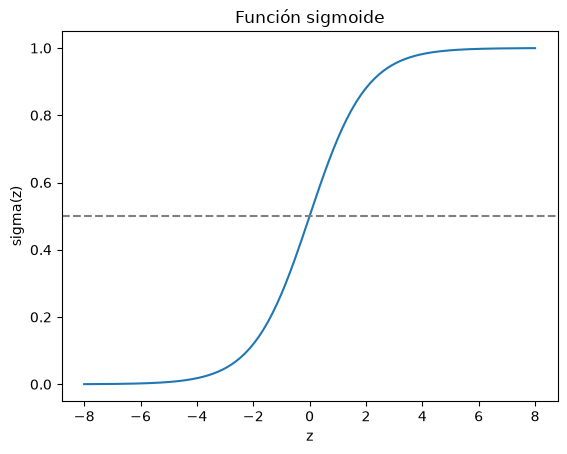

In [5]:
z = np.linspace(-8, 8, 200)
plt.plot(z, 1 / (1 + np.exp(-z)))
plt.axhline(0.5, ls="--", c="gray")
plt.title("Función sigmoide"); plt.xlabel("z"); plt.ylabel("sigma(z)"); plt.show()

## 4. Entrenamiento
Se estandarizan las variables antes de ajustar el modelo.

In [6]:
modelo = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000, random_state=42))
modelo.fit(Xtr, ytr)
pred = modelo.predict(Xte)
proba = modelo.predict_proba(Xte)[:, 1]

## 5. Evaluación

In [7]:
print("Exactitud :", round(accuracy_score(yte, pred), 4))
print("Precisión :", round(precision_score(yte, pred), 4))
print("Recall    :", round(recall_score(yte, pred), 4))
print("F1        :", round(f1_score(yte, pred), 4))
print("AUC       :", round(roc_auc_score(yte, proba), 4))
print()
print(classification_report(yte, pred, target_names=["Maligno", "Benigno"]))

Exactitud : 0.986
Precisión : 0.9889
Recall    : 0.9889
F1        : 0.9889
AUC       : 0.9977

              precision    recall  f1-score   support

     Maligno       0.98      0.98      0.98        53
     Benigno       0.99      0.99      0.99        90

    accuracy                           0.99       143
   macro avg       0.99      0.99      0.99       143
weighted avg       0.99      0.99      0.99       143



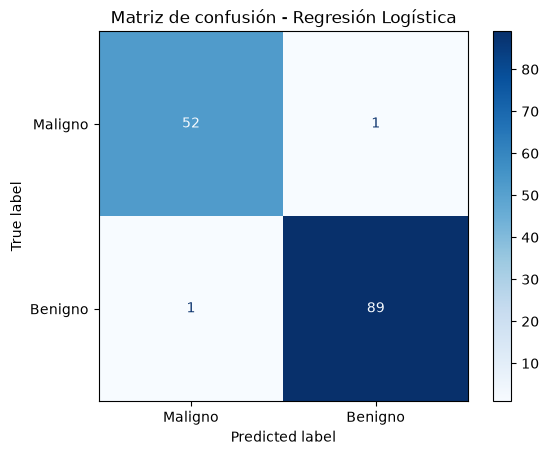

In [8]:
ConfusionMatrixDisplay(confusion_matrix(yte, pred), display_labels=["Maligno", "Benigno"]).plot(cmap="Blues")
plt.title("Matriz de confusión - Regresión Logística"); plt.show()

## 6. Interpretación de coeficientes

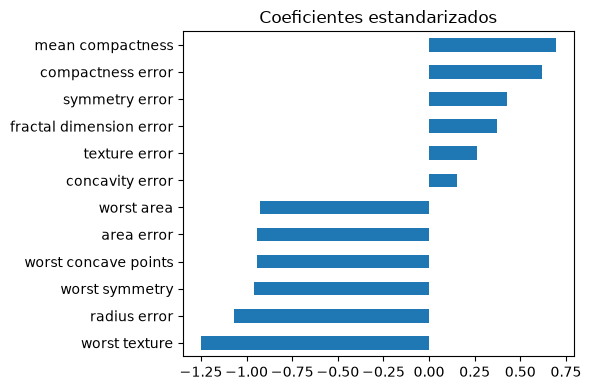

In [9]:
coefs = pd.Series(modelo[-1].coef_[0], index=X.columns).sort_values()
pd.concat([coefs.head(6), coefs.tail(6)]).plot.barh(figsize=(6, 4))
plt.title("Coeficientes estandarizados"); plt.tight_layout(); plt.show()

## 7. Efecto del umbral de decisión

In [10]:
filas = []
for t in [0.3, 0.5, 0.7, 0.9]:
    p = (proba >= t).astype(int)
    filas.append({"Umbral": t, "Precisión": precision_score(yte, p), "Recall": recall_score(yte, p),
                  "FN": int(((p == 0) & (yte == 1)).sum()), "FP": int(((p == 1) & (yte == 0)).sum())})
pd.DataFrame(filas).round(4)

,Umbral,Precisión,Recall,FN,FP
0,0.3,0.9677,1.0000,0,3
1,0.5,0.9889,0.9889,1,1
2,0.7,0.9882,0.9333,6,1
3,0.9,1.0000,0.8778,11,0
